## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

In [1]:
## 
import pandas as pd
import kagglehub
import os
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python

#df = pd.read_csv("amz_uk_price_prediction_dataset.csv") ## si el fichero esta en la misma carpeta que el script, leer fichero del mi pc

# Download latest version 
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
print("Path to dataset files:", path)

file_path = os.path.join(path, "amz_uk_price_prediction_dataset.csv")
df = pd.read_csv(file_path)
data=df


Path to dataset files: C:\Users\menot\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [2]:
data.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

In [3]:
### 1 - 1 - Crosstab Analysis

num = data.select_dtypes(include="number")
cat = data.select_dtypes(exclude="number")
## Define a numerical variables and a categorical variables
#data.describe()
cat.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [4]:
category = cat['category']
best_seller = cat['isBestSeller']

#crosstab_cat_best = pd.crosstab(category, best_seller, normalize='index')
crosstab_cat_best = pd.crosstab(category, best_seller)
crosstab_cat_best.sort_values(by=True, ascending=False)
print(crosstab_cat_best.to_string())


isBestSeller                                       False  True 
category                                                       
3D Printers                                          247      1
3D Printing & Scanning                              4065      2
Abrasive & Finishing Products                        245      5
Action Cameras                                      1696      1
Adapters                                             251      3
Agricultural Equipment & Supplies                   8421    109
Alexa Built-In Devices                               106      1
Art & Craft Supplies                                 253      5
Arts & Crafts                                       9319    230
Baby                                               14709    341
Baby & Toddler Toys                                 9332     24
Bakeware                                             233      6
Ballet & Dancing Footwear                           3238      2
Barebone PCs                            

##### Are there categories where being a best-seller is more prevalent? 
No, no category has more than 6% bestsellers, so the most frequent thing is NO Bestsellers

In [ ]:
### 1 - 2 - Statistical Tests

### Chi Square
from scipy.stats import chi2_contingency
### variables
_, chi2_pvalue , _, _ = chi2_contingency(crosstab_cat_best)
##print("Chi-cuadrado:", chi2)
print("Chi2 p-valor:", chi2_pvalue)
##print("Grados de libertad:", dof)


p-valor: 1.0


#### RESULT
p-valor of Chi Square is 1.0, greater than 0.05 , therefore there is no evidence of a relationship between category and iBestSeller.


In [44]:
from scipy.stats.contingency import association
### V Cramer
v_cramers = association(crosstab_cat_best,method='cramer')

print("V de Cramér:", v_cramers)

V de Cramér: 0.1222829439760564


#### RESULT 
v Cramer is 0.1222 weak relationship but some relationship

#### TOTAL RESULT
- p-valor of Chi Square is 1.0
- v Cramer is 0.1222

Knowing the category gives you very little information about whether a product will be a bestseller

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

In [5]:
data.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [6]:
### 2-0 - Remove outliers in product prices 

q1 = data['price'].quantile(0.25)
q3 = data['price'].quantile(0.75)
iqr=q3-q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
data_no_atip = data[(data['price'] >= lower_bound) & (data['price'] <= upper_bound)]
print("q1:",q1)
print("q3:",q3)
print("iqr:",iqr)
print("lower_bound:",lower_bound)
print("upper_bound:",upper_bound)

q1: 9.99
q3: 45.99
iqr: 36.0
lower_bound: -44.01
upper_bound: 99.99000000000001


In [7]:
### info post remove
print("Original:", len(data))
print("without atípics:", len(data_no_atip))
print("Removed:", len(data) - len(data_no_atip))
print("% Removed:", ((len(data) - len(data_no_atip))*100)/len(data))

Original: 2443651
without atípics: 2115963
Removed: 327688
% Removed: 13.409770871536075


In [8]:
### review de data result without atipics (only products in price range 0-99,99)
data_no_atip.head(100)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
164,166,B0CCYFP62W,"Sony SRS-XB100 - Wireless Bluetooth, Portable,...",4.6,134,52.00,False,0,Hi-Fi Speakers
168,170,B07ZNJCP6N,"Aisung Soundbar for TV, 32-inch Home Theater S...",3.9,372,32.99,False,0,Hi-Fi Speakers
169,171,B09QL89J8X,"Bluetooth Speakers, 60W(80W Peak) Portable Lou...",3.9,252,55.98,False,0,Hi-Fi Speakers
170,172,B084TNNZYR,Certified and Refurbished Echo Show 8 | 2nd ge...,4.6,294,58.99,False,0,Hi-Fi Speakers


In [9]:
### TOP 20 categories & data of top20 for graphs
##top20
top20 = (
    data.groupby('category', as_index=False)['boughtInLastMonth']
    .sum()
    .sort_values('boughtInLastMonth', ascending=False)
    .head(20)
)
print(top20)
top20_categories = top20['category'].tolist()
print(top20_categories)
### data top20
data_t20_no_atip = data_no_atip[data_no_atip['category'].isin(top20_categories)]
data_t20_no_atip.describe()


                             category  boughtInLastMonth
126            Health & Personal Care            9626950
109                           Grocery            8442550
20                             Beauty            7052400
221                      Pet Supplies            3231650
9                                Baby            2635150
111                         Hair Care            2102550
251                         Skin Care            2098050
8                       Arts & Crafts            1934350
266            Storage & Organisation            1814350
210                   Office Supplies            1317500
16                        Bath & Body            1148700
176                           Make-up            1048950
102                         Gardening             990150
209             Office Paper Products             933300
177      Manicure & Pedicure Products             713500
262                 Sports & Outdoors             696500
220  Pens, Pencils & Writing Su

,uid,stars,reviews,price,boughtInLastMonth
count,9.398430e+05,939843.000000,9.398430e+05,939843.000000,939843.000000
mean,1.273070e+06,1.661700,3.524919e+02,22.136298,51.187220
std,7.475665e+05,2.128625,2.843014e+03,19.420952,359.787678
min,2.691700e+04,0.000000,0.000000e+00,0.000000,0.000000
25%,5.499875e+05,0.000000,0.000000e+00,8.930000,0.000000
50%,1.155365e+06,0.000000,0.000000e+00,15.190000,0.000000
75%,1.993154e+06,4.300000,2.600000e+01,28.940000,0.000000
max,2.818786e+06,5.000000,1.352534e+06,99.990000,50000.000000


C:\Users\menot\AppData\Local\Temp\ipykernel_22720\1681710874.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data_t20_no_atip, x="category", y="price", palette="coolwarm")


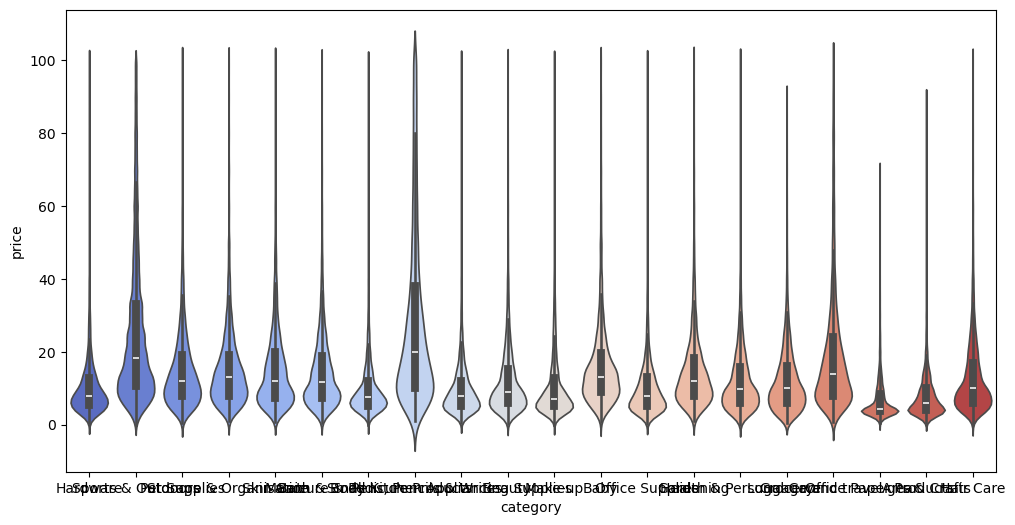

In [10]:
#### 2 - 1 Violin Plots
plt.figure(figsize=(12,6))
sns.violinplot(data=data_t20_no_atip, x="category", y="price", palette="coolwarm")
plt.show()


Which product category commands the highest average price? Don't filter here by top categories.

In [11]:
### Mean price dataframe 

mean_price = (
    data_no_atip.groupby('category')['price']  ## data no filtred by top20 but without atipics 
    .mean()
    .sort_values(ascending=False)
)

print("Category commands the highest average price:")
print(mean_price.head(1))
### in variables
category_top = mean_price.idxmax()
value_top = mean_price.max()

print("Category top:",category_top, "Top value:",value_top)


Category commands the highest average price:
category
Motherboards    68.772432
Name: price, dtype: float64
Category top: Motherboards Top value: 68.77243243243242


In [12]:
### 2-2 Bar Charts

### TOP 10 categories & data of top10 for graphs
top10_categories = top20_categories[:10]
print(top10_categories)
### data top20
data_t10_no_atip = data_no_atip[data_no_atip['category'].isin(top10_categories)]

### mean price top10
mean_price_top10_df = (
    data_t10_no_atip
    .groupby('category',as_index=False)['price']  ## change for output a df  "as_index=False"--> don't use category like index leave it as a normal column
    .mean()
    .sort_values('price',ascending=False)  ## change 'price' for output a df 
)
print(type(data_t10_no_atip))
print(type(mean_price_top10_df))



['Health & Personal Care', 'Grocery', 'Beauty', 'Pet Supplies', 'Baby', 'Hair Care', 'Skin Care', 'Arts & Crafts', 'Storage & Organisation', 'Office Supplies']
<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


C:\Users\menot\AppData\Local\Temp\ipykernel_22720\4266530578.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


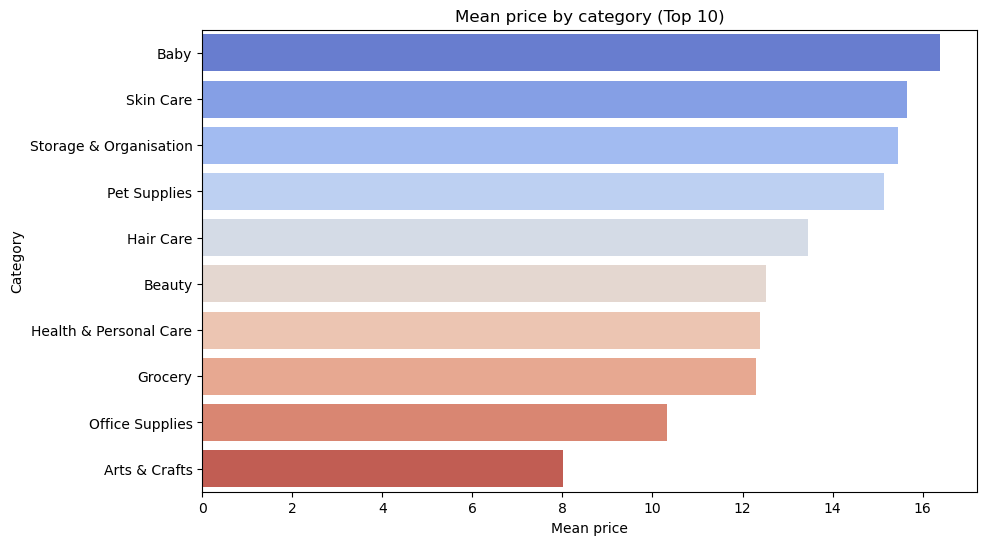

In [13]:
### Bar chart

plt.figure(figsize=(10, 6))

sns.barplot(
    data=mean_price_top10_df,
    x='price',
    y='category',
    palette="coolwarm", 
    errorbar=None
)

plt.title('Mean price by category (Top 10)')
plt.xlabel('Mean price')
plt.ylabel('Category')

plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

1. **Correlation Coefficients**:
    - 1.1 - Calculate the correlation coefficient between `price` and `stars`.

In [15]:
# Coefficient of Spearman ## better for ordinal data like stars
correlation = data['price'].corr(data['stars'], method='spearman')
print(f"Coefficient of Spearman: {correlation}")

Coefficient of Spearman: -0.13316425462433912


In [16]:
# Coefficient of Pearson ## not good for ordinal data like stars
pearson_corr = data['price'].corr(data['stars'], method='pearson')

print(f"Coefficient of Pearson: {pearson_corr}")

Coefficient of Pearson: -0.12490673262148638


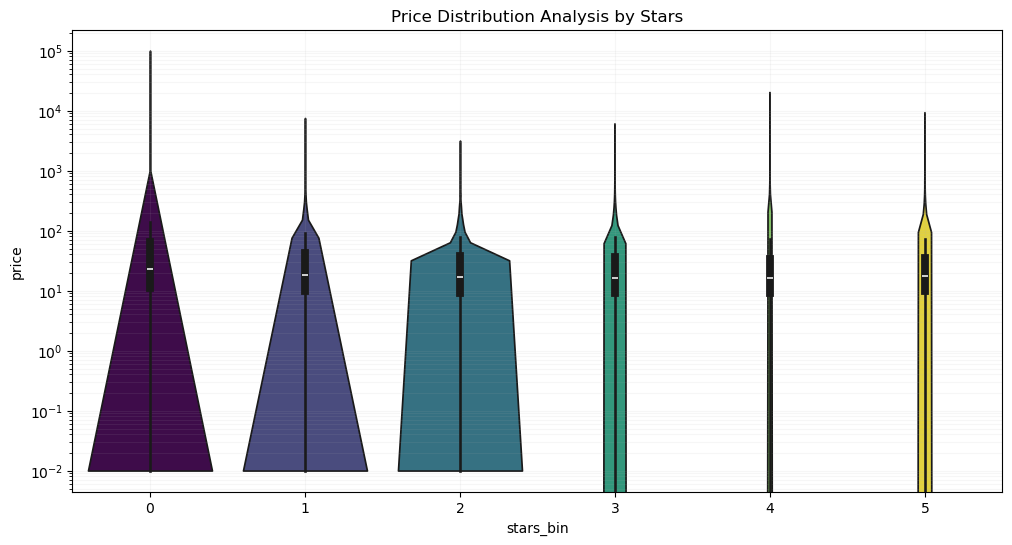

In [26]:
plt.figure(figsize=(12, 6))


sns.violinplot(x='stars_bin', y='price', data=data, 
               palette="viridis", hue='stars_bin', legend=False,
               bw_adjust=0.5, cut=0)

plt.yscale('log')
plt.title('Price Distribution Analysis by Stars')
plt.grid(True, which="both", ls="-", alpha=0.1)
plt.show()

- 1.2 - Is there a significant correlation between product price and its rating?
- - **NO. There is almost total independence between price and rating. The correlation coefficient of -0.13 is low because the median price is constant across all categories, with the exception of some outliers of extremely high prices for low-rated products.**

2. **Visualizations**:

- 2.1 - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?


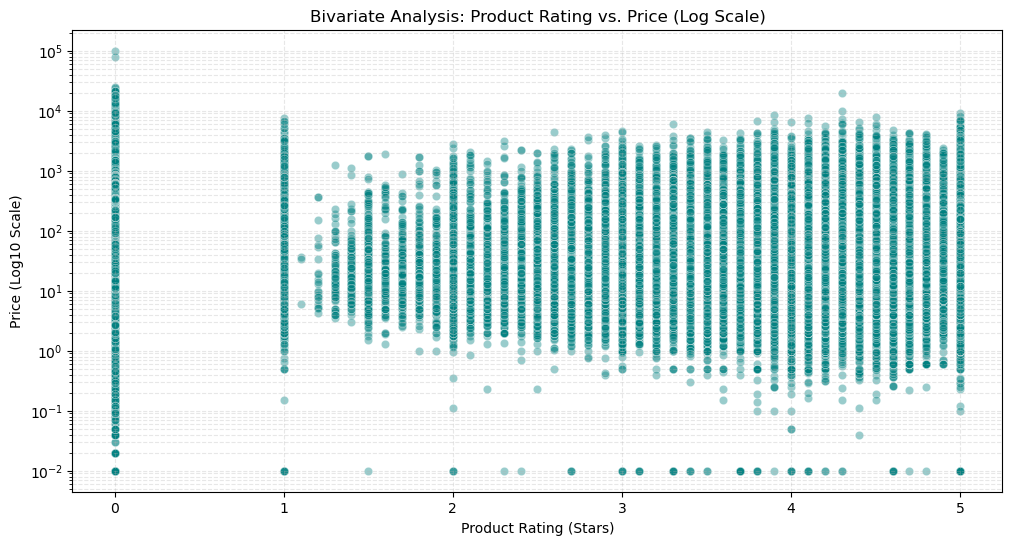

In [27]:
plt.figure(figsize=(12, 6))

# Create the scatter plot

sns.scatterplot(x='stars', y='price', data=data, alpha=0.4, color='teal')

# Apply logarithmic scale to Y-axis to handle the 100k outlier
plt.yscale('log')

plt.title('Bivariate Analysis: Product Rating vs. Price (Log Scale)')
plt.xlabel('Product Rating (Stars)')
plt.ylabel('Price (Log10 Scale)')

# grid 
plt.grid(True, which="both", linestyle='--', alpha=0.3)
plt.show()

Pattern Interpretation:
Vertical Stripes: Vertical columns are observed. This confirms that this is a categorical rather than a numerical relationship.
Density Concentration: The darkest areas are at the bottom of the graph, meaning that the vast majority of the data consists of low-priced products across all star ratings.
Outlier Influence: The isolated points at the top (near $10^5) represent expensive products with low ratings. This is the primary reason for their negative correlation of -0.13.
Random Distribution: There is no visible upward or downward slope in the "cloud" of points. This indicates that price is not a strong predictor of rating in this dataset.

- 2.2 - Use a correlation heatmap to visualize correlations between all numerical variables.
   

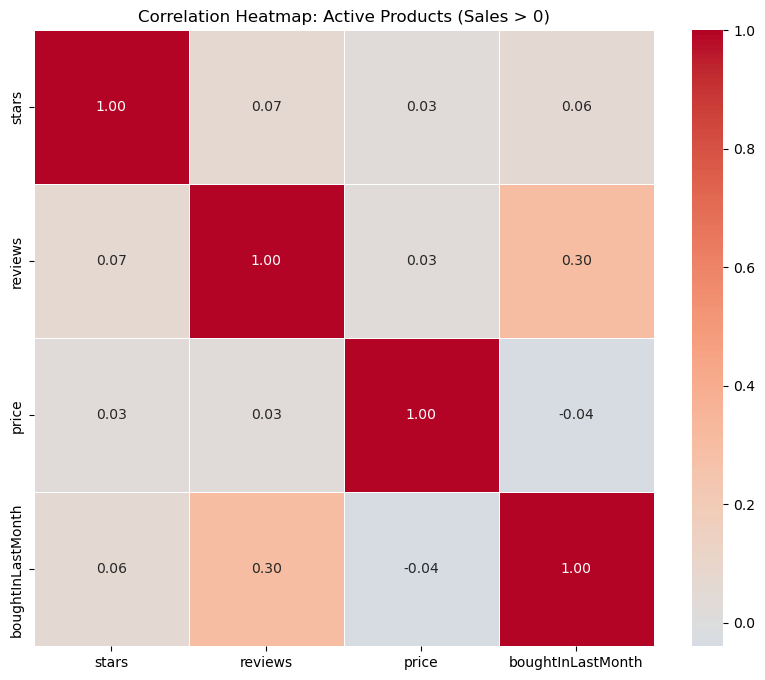

Analysis performed on 213,447 active records.


In [41]:

# Filtering for products with at least one sale to focus on active market data
active_products = data[data['boughtInLastMonth'] > 0]

# Selecting the relevant numerical columns for the heatmap, we use the raw variables to see the real statistical relationship
numerical_cols = ['stars', 'reviews', 'price', 'boughtInLastMonth']
correlation_matrix = active_products[numerical_cols].corr()

plt.figure(figsize=(10, 8))

# Blue for negative correlations and Red for positive ones
sns.heatmap(correlation_matrix, 
            annot=True, 
            cmap='coolwarm', 
            fmt=".2f", 
            linewidths=0.5, 
            center=0)

plt.title('Correlation Heatmap: Active Products (Sales > 0)')
plt.show()

print(f"Analysis performed on {len(active_products):,} active records.")

- 2.3 - Examine if product prices typically follow a normal distribution using a QQ plot. 

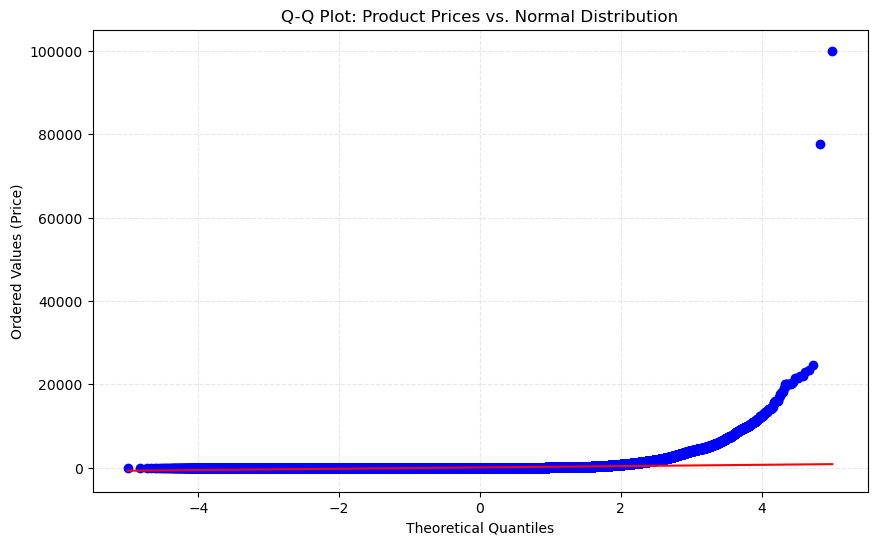

In [43]:
import scipy.stats as stats
plt.figure(figsize=(10, 6))

# Generate the Q-Q plot
# 'dist="norm"' compares your data against a normal distribution
stats.probplot(data['price'], dist="norm", plot=plt)

plt.title('Q-Q Plot: Product Prices vs. Normal Distribution')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Ordered Values (Price)')
plt.grid(True, linestyle='--', alpha=0.3)

plt.show()

#### Interpretation of the Q-Q Plot:
The vast majority of the points are at the bottom, and then there's a sharp rise at the end. This confirms that prices do NOT follow a normal distribution. The distribution is heavily skewed to the right, with a long tail of high-priced products. This is consistent with the presence of outliers and the concentration of low-priced products observed in the scatter plot.